# 05. Implementación del modelo de Regresión Logística

En este cuaderno implemento un modelo de Regresión Logística para predecir el resultado de los partidos de la Liga Panameña de Fútbol.

Planteo el problema como una clasificación multiclase con tres posibles resultados: victoria local (`L`), empate (`E`) y victoria visitante (`V`).

Utilizo exclusivamente el conjunto de entrenamiento para ajustar las transformaciones y los parámetros del modelo. Empleo el conjunto de validación para comparar diferentes configuraciones y mantengo el conjunto de prueba completamente separado hasta seleccionar la versión definitiva.

Durante la evaluación considero métricas globales y métricas por clase, con especial atención al F1-Score Macro, debido a que las tres categorías presentan frecuencias diferentes y mi objetivo es evaluar de manera equilibrada el desempeño sobre victorias locales, empates y victorias visitantes.

# Celda 2 Librerías

In [43]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


# Celda 3 Rutas y carga de datos
## 1. Carga de los conjuntos de datos
Cargo los conjuntos de entrenamiento, validación y prueba generados mediante la separación temporal realizada previamente.

Mantengo los tres subconjuntos de manera independiente para evitar que la información correspondiente a periodos posteriores intervenga durante el ajuste de la Regresión Logística.

In [44]:
ROOT = Path("..").resolve()

PROCESSED_DIR = (
    ROOT
    / "data"
    / "processed"
)

FIGURES_DIR = (
    ROOT
    / "figures"
)

MODELS_DIR = (
    ROOT
    / "models"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATH = (
    PROCESSED_DIR
    / "lpf_train.csv"
)

VALIDACION_PATH = (
    PROCESSED_DIR
    / "lpf_validacion.csv"
)

TEST_PATH = (
    PROCESSED_DIR
    / "lpf_test.csv"
)

df_train = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_validacion = pd.read_csv(
    VALIDACION_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_test = pd.read_csv(
    TEST_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

print(
    "Entrenamiento:",
    df_train.shape
)

print(
    "Validación:",
    df_validacion.shape
)

print(
    "Prueba:",
    df_test.shape
)

Entrenamiento: (1869, 55)
Validación: (206, 55)
Prueba: (151, 55)


# Celda 4 Comprobación temporal
### 1.1. Comprobación temporal
Antes de entrenar el modelo verifico nuevamente que el conjunto de entrenamiento corresponda a un periodo anterior al conjunto de validación y que el conjunto de prueba permanezca cronológicamente posterior a ambos.

In [45]:
print(
    "Train:",
    df_train["fecha_partido"].min(),
    "→",
    df_train["fecha_partido"].max()
)

print(
    "Validación:",
    df_validacion["fecha_partido"].min(),
    "→",
    df_validacion["fecha_partido"].max()
)

print(
    "Prueba:",
    df_test["fecha_partido"].min(),
    "→",
    df_test["fecha_partido"].max()
)

assert (
    df_train["fecha_partido"].max()
    <
    df_validacion["fecha_partido"].min()
)

assert (
    df_validacion["fecha_partido"].max()
    <
    df_test["fecha_partido"].min()
)

print(
    "\nSeparación temporal correcta."
)

Train: 2014-07-18 00:00:00 → 2024-11-30 00:00:00
Validación: 2025-01-17 00:00:00 → 2025-11-29 00:00:00
Prueba: 2026-01-16 00:00:00 → 2026-09-14 00:00:00

Separación temporal correcta.


# Celda 5  Definir predictores
## 2. Definición de variables predictoras y objetivo
Separo las características utilizadas como entrada de aquellas variables que únicamente sirven para identificación, trazabilidad o evaluación.
Excluyo expresamente los goles finales y el resultado del encuentro de las variables predictoras. Mantengo como objetivo de clasificación la variable `resultado`.
Aunque `mes_partido` y `dia_semana` se almacenan mediante números enteros, los considero variables categóricas porque sus valores representan categorías temporales y no magnitudes continuas.

In [46]:
columnas_no_predictoras = [
    "registro_id",
    "fecha_partido",
    "temporada",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado"
]

columnas_categoricas = [
    "home_team_name",
    "away_team_name",
    "mes_partido",
    "dia_semana"
]

columnas_numericas = [
    columna
    for columna in df_train.columns
    if (
        columna
        not in columnas_no_predictoras
        and columna
        not in columnas_categoricas
    )
]

columnas_X = (
    columnas_numericas
    + columnas_categoricas
)

print(
    "Variables numéricas:",
    len(columnas_numericas)
)

print(
    "Variables categóricas:",
    len(columnas_categoricas)
)

print(
    "Total de predictores:",
    len(columnas_X)
)

Variables numéricas: 44
Variables categóricas: 4
Total de predictores: 48


# Celda 6. Extracción formal de las matrices de entrada  y vectores objetivo
# Construcción de los subconjuntos de entrada y salida
Una vez aisladas las particiones temporales y definidas las listas de variables predictoras, extraigo formalmente las matrices de características de entrada (X_train, X_validacion, X_test) y los vectores que contienen la variable objetivo (y_train, y_validacion, y_test).En esta celda utilizo .copy() para asegurar la independencia en memoria de cada subconjunto. Al separar la matriz de características del vector de etiquetas (resultado), garantizo que las fases posteriores de entrenamiento y evaluación reciban únicamente la estructura necesaria, verificando las dimensiones resultantes en cada partición.

In [47]:
# extraer las matrices de entrada y vectores objetivo para entrenamiento
X_train = (
    df_train[
        columnas_X
    ].copy()
)

y_train = (
    df_train[
        "resultado"
    ].copy()
)

# extraer las matrices de entrada y vectores objetivo para validación
X_validacion = (
    df_validacion[
        columnas_X
    ].copy()
)

y_validacion = (
    df_validacion[
        "resultado"
    ].copy()
)

# extraer las matrices de entrada y vectores objetivo para prueba
X_test = (
    df_test[
        columnas_X
    ].copy()
)

y_test = (
    df_test[
        "resultado"
    ].copy()
)

# mostrar las dimensiones finales de cada subconjunto
print(
    "X_train:",
    X_train.shape,
    "| y_train:",
    y_train.shape
)

print(
    "X_validación:",
    X_validacion.shape,
    "| y_validación:",
    y_validacion.shape
)

print(
    "X_test:",
    X_test.shape,
    "| y_test:",
    y_test.shape
)

X_train: (1869, 48) | y_train: (1869,)
X_validación: (206, 48) | y_validación: (206,)
X_test: (151, 48) | y_test: (151,)


# Celda 7 Baseline de validación
### 2.1. Línea base de referencia
Utilizo como referencia la estrategia trivial definida en la etapa anterior: predecir siempre la clase mayoritaria observada en el conjunto de entrenamiento.Esta línea base me permitirá determinar si la Regresión Logística aporta una mejora real sobre una decisión que no utiliza ninguna característica del partido.

In [48]:
clase_baseline = (
    y_train
    .value_counts()
    .idxmax()
)

baseline_validacion = (
    y_validacion
    .eq(clase_baseline)
    .mean()
)

print(
    "Clase baseline:",
    clase_baseline
)

print(
    "Accuracy baseline en validación:",
    round(
        baseline_validacion * 100,
        2
    ),
    "%"
)

Clase baseline: L
Accuracy baseline en validación: 36.41 %


# Celda 8 Pipeline de preprocesamiento
## 3. Preprocesamiento de las variables
Construyo un procedimiento de transformación diferenciado para las variables numéricas y categóricas.
Para las variables numéricas sustituyo los valores faltantes utilizando la mediana calculada exclusivamente sobre los datos de entrenamiento y posteriormente aplico escalado Min-Max.
Para las variables categóricas sustituyo posibles valores faltantes mediante la categoría más frecuente y aplico codificación One-Hot.
Configuro el codificador con `handle_unknown="ignore"` para permitir que el modelo procese categorías no observadas durante el entrenamiento, como equipos que aparecen posteriormente en validación o prueba.
Integro todas las transformaciones dentro de un `Pipeline`, evitando ajustar manualmente el preprocesamiento sobre el conjunto completo.

In [49]:
pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            MinMaxScaler()
        )
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocesador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            columnas_numericas
        ),
        (
            "categoricas",
            pipeline_categorico,
            columnas_categoricas
        )
    ]
)

print(
    "Pipeline de preprocesamiento construido."
)

Pipeline de preprocesamiento construido.


# Celda 9 Regresión Logística base
## 4. Entrenamiento del modelo base
Como primera aproximación entreno una Regresión Logística utilizando un nivel de regularización estándar (`C = 1.0`) y sin aplicar ponderación adicional a las clases.
Utilizo el algoritmo `lbfgs` y establezco un número máximo elevado de iteraciones para facilitar la convergencia del modelo.
Esta configuración inicial servirá como referencia antes de explorar diferentes intensidades de regularización y estrategias de balance de clases.

In [50]:
modelo_base = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "modelo",
            LogisticRegression(
                C=1.0,
                class_weight=None,
                solver="lbfgs",
                max_iter=3000,
                random_state=42
            )
        )
    ]
)

modelo_base.fit(
    X_train,
    y_train
)

print(
    "Modelo base entrenado correctamente."
)

Modelo base entrenado correctamente.


# Celda 10. Generación de predicciones y probabilidades sobre el conjunto de validación
# Inferencia del modelo base en validación
Una vez ajustado el estimador o pipeline de referencia (modelo_base), utilizo el subconjunto de validación (X_validacion) para obtener tanto las etiquetas predichas como las probabilidades estimadas para cada una de las tres clases de la competición ("L", "E", "V").

En esta celda ejecuto los métodos .predict() y .predict_proba() sobre X_validacion. Verifico que la cantidad de predicciones coincida con el número de observaciones de validación, que las dimensiones de la matriz de probabilidades reflejen las tres categorías objetivo y extraigo el atributo .classes_ del paso final del pipeline para conocer la asignación exacta de las columnas de probabilidad.

In [51]:
# generar etiquetas predichas para el conjunto de validación
pred_validacion_base = (
    modelo_base.predict(
        X_validacion
    )
)

# generar probabilidades asignadas a cada clase (L, E, V)
proba_validacion_base = (
    modelo_base.predict_proba(
        X_validacion
    )
)

# mostrar métricas de verificación de la inferencia
print(
    "Predicciones generadas:",
    len(pred_validacion_base)
)

print(
    "Matriz de probabilidades:",
    proba_validacion_base.shape
)

print(
    "Orden de clases:",
    modelo_base.named_steps[
        "modelo"
    ].classes_
)

Predicciones generadas: 206
Matriz de probabilidades: (206, 3)
Orden de clases: ['E' 'L' 'V']


# Celda 11 Métricas globales
### 4.1. Evaluación inicial sobre el conjunto de validación
Evalúo inicialmente el modelo sobre los partidos correspondientes al conjunto de validación.
Utilizo Accuracy como medida general de aciertos y complemento el análisis mediante Precision, Recall y F1-Score calculados con promedio Macro. De esta manera otorgo el mismo peso a las tres clases, independientemente de su frecuencia.
También calculo Log Loss para evaluar la calidad de las probabilidades asignadas por el modelo y no únicamente la clase finalmente seleccionada.

In [52]:
metricas_base = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_validacion_base
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_validacion_base,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_validacion_base,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_validacion_base,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion,
        proba_validacion_base,
        labels=modelo_base.named_steps[
            "modelo"
        ].classes_
    )
}

for metrica, valor in metricas_base.items():
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3738
precision_macro: 0.3568
recall_macro: 0.3646
f1_macro: 0.3514
log_loss: 1.1326


# Celda 12. Comparación cuantitativa del modelo contra la línea base (Baseline)
# Evaluación de ganancia respecto al clasificador trivial
Evalúo el desempeño relativo del modelo de referencia contrastando su exactitud (Accuracy) frente al rendimiento de la línea base en el conjunto de validación (baseline_validacion).

En esta celda calculo la diferencia absoluta en puntos porcentuales (mejora_accuracy) entre la exactitud del modelo y la estrategia trivial de asignación de la clase mayoritaria. Esta comparación permite cuantificar el valor predictivo real aportado por las características estructuradas y la arquitectura del modelo sobre una regla de decisión ingenua.

In [53]:
# calcular la mejora porcentual en exactitud respecto al baseline
mejora_accuracy = (
    metricas_base["accuracy"]
    - baseline_validacion
)

# mostrar métricas comparativas formateadas
print(
    "Accuracy modelo:",
    round(
        metricas_base[
            "accuracy"
        ] * 100,
        2
    ),
    "%"
)

print(
    "Accuracy baseline:",
    round(
        baseline_validacion * 100,
        2
    ),
    "%"
)

print(
    "Diferencia:",
    round(
        mejora_accuracy * 100,
        2
    ),
    "puntos porcentuales"
)

Accuracy modelo: 37.38 %
Accuracy baseline: 36.41 %
Diferencia: 0.97 puntos porcentuales


# Celda 13 Reporte por clase
### 4.2. Rendimiento individual por categoría
Analizo el comportamiento de la Regresión Logística para cada una de las tres clases.
Esta revisión me permite identificar si una métrica global aparentemente favorable oculta dificultades importantes en alguna categoría específica, especialmente en la predicción de empates.

In [54]:
reporte_base = (
    classification_report(
        y_validacion,
        pred_validacion_base,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_base = (
    pd.DataFrame(
        reporte_base
    )
    .T
)

display(
    df_reporte_base.round(4)
)

,precision,recall,f1-score,support
L,0.4074,0.5867,0.4809,75.0000
E,0.2667,0.1791,0.2143,67.0000
V,0.3962,0.3281,0.3590,64.0000
accuracy,0.3738,0.3738,0.3738,0.3738
macro avg,0.3568,0.3646,0.3514,206.0000
weighted avg,0.3582,0.3738,0.3563,206.0000


# Celda 14. Matriz de confusión para la evaluación detallada de aciertos por clase
# Inspección de desaciertos y matriz de confusión
Para comprender la distribución de los errores del modelo base sobre el conjunto de validación, construyo la matriz de confusión especificando el orden explícito de las etiquetas (["L", "E", "V"]).

En esta celda utilizo confusion_matrix de scikit-learn y la estructuro dentro de un DataFrame de pandas con índices ("Real L", "Real E", "Real V") y columnas ("Pred L", "Pred E", "Pred V"). Esta representación tabular me permite analizar el sesgo de predicción del modelo e identificar si la principal dificultad radica en la distinción entre victorias y empates.

In [55]:
# calcular la matriz de confusión especificando el orden formal de clases
matriz_base = confusion_matrix(
    y_validacion,
    pred_validacion_base,
    labels=[
        "L",
        "E",
        "V"
    ]
)

# estructurar la matriz en un DataFrame etiquetado para visualización
df_matriz_base = pd.DataFrame(
    matriz_base,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

# desplegar la matriz de confusión de validación
display(df_matriz_base)

,Pred L,Pred E,Pred V
Real L,44,15,16
Real E,39,12,16
Real V,25,18,21


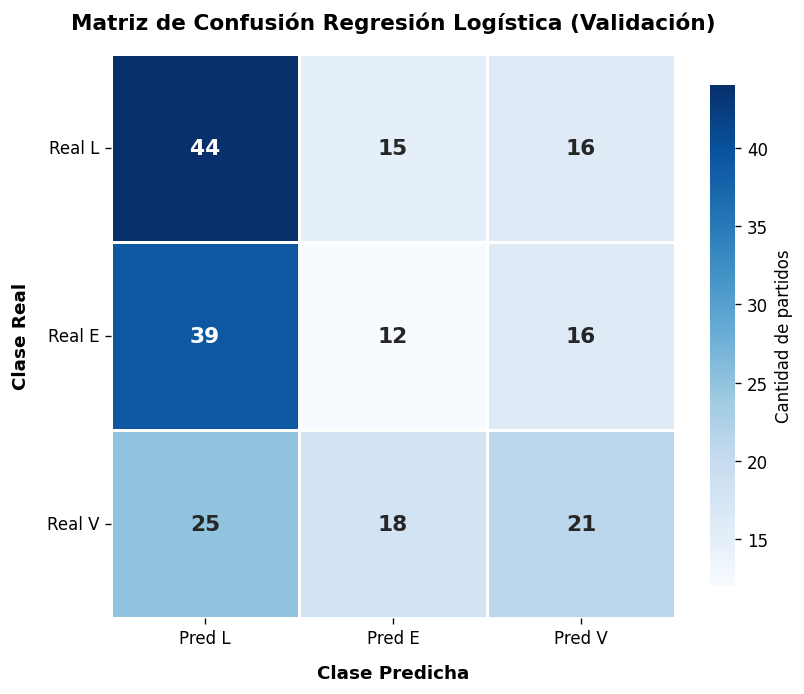

In [56]:
# configurar el estilo estético global para la figura
fig, ax = plt.subplots(
    figsize=(7, 6),
    dpi=120
)

# generar mapa de calor con bordes limpios y formato de etiquetas enriquecido
sns.heatmap(
    df_matriz_base,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=1.5,
    linecolor="white",
    square=True,
    annot_kws={
        "size": 13,
        "weight": "bold"
    },
    cbar_kws={
        "shrink": 0.82,
        "label": "Cantidad de partidos"
    },
    ax=ax
)

# personalizar título, ejes y etiquetas
ax.set_title(
    "Matriz de Confusión Regresión Logística (Validación)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Clase Predicha",
    fontsize=11,
    fontweight="semibold",
    labelpad=10
)

ax.set_ylabel(
    "Clase Real",
    fontsize=11,
    fontweight="semibold",
    labelpad=10
)

# ajustar rotación de etiquetas para mayor legibilidad
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0,
    fontsize=10
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=10
)

# optimizar la disposición de elementos gráficos
plt.tight_layout()

# definir ruta de destino y exportar en alta resolución
RUTA_FIGURA = (
    FIGURES_DIR
    / "regresion_logistica_base_validacion.png"
)

plt.savefig(
    RUTA_FIGURA,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Celda 15  Distribución de las predicciones
### 4.3. Distribución de las clases predichas
Comparo la cantidad de predicciones asignadas a cada categoría con la distribución real del conjunto de validación.
Esta comprobación me permite detectar comportamientos como la concentración excesiva de predicciones en una sola clase o la escasa utilización de alguna categoría.

In [57]:
comparacion_clases = pd.DataFrame({
    "Real": (
        y_validacion
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_validacion_base
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

display(
    comparacion_clases
)

,Real,Predicho
L,75,108
E,67,45
V,64,53


## 5. Ajuste de la Regresión Logística
Comparo diferentes niveles de regularización mediante el parámetro `C` y evalúo tanto el entrenamiento convencional como la ponderación automática de las clases mediante `class_weight="balanced"`.
Realizo todas las comparaciones exclusivamente sobre el conjunto de validación. Utilizo el F1-Score Macro como criterio principal para seleccionar la configuración, ya que busco un desempeño equilibrado entre las tres posibles clases.

El conjunto de prueba no interviene en esta etapa.

In [58]:
valores_C = [
    0.01,
    0.1,
    1,
    10,
    100
]

pesos_clase = [
    None,
    "balanced"
]

resultados_configuraciones = []

for C in valores_C:

    for class_weight in pesos_clase:

        pipeline_actual = Pipeline(
            steps=[
                (
                    "preprocesamiento",
                    preprocesador
                ),
                (
                    "modelo",
                    LogisticRegression(
                        C=C,
                        class_weight=class_weight,
                        solver="lbfgs",
                        max_iter=3000,
                        random_state=42
                    )
                )
            ]
        )

        pipeline_actual.fit(
            X_train,
            y_train
        )

        pred_actual = (
            pipeline_actual.predict(
                X_validacion
            )
        )

        proba_actual = (
            pipeline_actual.predict_proba(
                X_validacion
            )
        )

        resultados_configuraciones.append({
            "C": C,

            "class_weight": (
                "None"
                if class_weight is None
                else class_weight
            ),

            "accuracy": accuracy_score(
                y_validacion,
                pred_actual
            ),

            "precision_macro":
                precision_score(
                    y_validacion,
                    pred_actual,
                    average="macro",
                    zero_division=0
                ),

            "recall_macro":
                recall_score(
                    y_validacion,
                    pred_actual,
                    average="macro",
                    zero_division=0
                ),

            "f1_macro":
                f1_score(
                    y_validacion,
                    pred_actual,
                    average="macro",
                    zero_division=0
                ),

            "log_loss":
                log_loss(
                    y_validacion,
                    proba_actual,
                    labels=pipeline_actual.named_steps[
                        "modelo"
                    ].classes_
                )
        })

# Celda 17 Tabla comparativa

In [59]:
df_configuraciones = (
    pd.DataFrame(
        resultados_configuraciones
    )
    .sort_values(
        [
            "f1_macro",
            "accuracy"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    df_configuraciones.round(4)
)

,C,class_weight,accuracy,precision_macro,recall_macro,f1_macro,log_loss
0,0.01,balanced,0.3932,0.3774,0.3923,0.3765,1.0892
1,1.00,None,0.3738,0.3568,0.3646,0.3514,1.1326
2,0.10,balanced,0.3544,0.3498,0.3536,0.3498,1.1082
3,0.10,None,0.3786,0.3393,0.3689,0.3413,1.1076
4,1.00,balanced,0.3398,0.3397,0.3390,0.3382,1.1337
5,0.01,None,0.4126,0.4032,0.3939,0.3291,1.0891
6,10.00,None,0.3447,0.3241,0.3344,0.3205,1.1520
7,100.00,None,0.3398,0.3212,0.3305,0.3183,1.1668
8,10.00,balanced,0.3155,0.3170,0.3142,0.3148,1.1531
9,100.00,balanced,0.3107,0.3120,0.3098,0.3102,1.1685


# Celda 18 Mejor configuración

In [60]:
mejor_config = (
    df_configuraciones
    .iloc[0]
)

print(
    "Mejor configuración encontrada:"
)

print(
    "C:",
    mejor_config["C"]
)

print(
    "class_weight:",
    mejor_config[
        "class_weight"
    ]
)

print(
    "F1 Macro:",
    round(
        mejor_config[
            "f1_macro"
        ],
        4
    )
)

print(
    "Accuracy:",
    round(
        mejor_config[
            "accuracy"
        ],
        4
    )
)

print(
    "Precision Macro:",
    round(
        mejor_config[
            "precision_macro"
        ],
        4
    )
)

print(
    "Recall Macro:",
    round(
        mejor_config[
            "recall_macro"
        ],
        4
    )
)

print(
    "Log Loss:",
    round(
        mejor_config[
            "log_loss"
        ],
        4
    )
)

Mejor configuración encontrada:
C: 0.01
class_weight: balanced
F1 Macro: 0.3765
Accuracy: 0.3932
Precision Macro: 0.3774
Recall Macro: 0.3923
Log Loss: 1.0892


# Celda 19 Refinamiento alrededor de C = 0.01
## 6. Refinamiento de la regularización
La primera comparación mostró que la mejor configuración según F1-Score Macro utiliza `C = 0.01` y ponderación balanceada de clases.
Debido a que este valor corresponde al extremo inferior del rango inicialmente evaluado, realizo una búsqueda adicional únicamente alrededor de valores pequeños de `C`. Mi objetivo es comprobar si una regularización más intensa permite mejorar el equilibrio entre las tres clases.
Mantengo `class_weight="balanced"` debido a que esta estrategia obtuvo el mejor F1-Score Macro en la comparación anterior. Continúo utilizando exclusivamente el conjunto de validación y mantengo el conjunto de prueba sin utilizar.

In [61]:
valores_C_refinados = [
    0.001,
    0.0025,
    0.005,
    0.0075,
    0.01,
    0.015,
    0.02,
    0.03,
    0.05
]

resultados_refinados = []

for C in valores_C_refinados:

    pipeline_actual = Pipeline(
        steps=[
            (
                "preprocesamiento",
                preprocesador
            ),
            (
                "modelo",
                LogisticRegression(
                    C=C,
                    class_weight="balanced",
                    solver="lbfgs",
                    max_iter=3000,
                    random_state=42
                )
            )
        ]
    )

    pipeline_actual.fit(
        X_train,
        y_train
    )

    pred_actual = pipeline_actual.predict(
        X_validacion
    )

    proba_actual = pipeline_actual.predict_proba(
        X_validacion
    )

    resultados_refinados.append({
        "C": C,

        "accuracy": accuracy_score(
            y_validacion,
            pred_actual
        ),

        "precision_macro": precision_score(
            y_validacion,
            pred_actual,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_validacion,
            pred_actual,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_validacion,
            pred_actual,
            average="macro",
            zero_division=0
        ),

        "log_loss": log_loss(
            y_validacion,
            proba_actual,
            labels=pipeline_actual.named_steps[
                "modelo"
            ].classes_
        )
    })

# Celda 20 Resultados del refinamiento

In [62]:
df_refinamiento = (
    pd.DataFrame(
        resultados_refinados
    )
    .sort_values(
        [
            "f1_macro",
            "log_loss"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(
    df_refinamiento.round(4)
)

,C,accuracy,precision_macro,recall_macro,f1_macro,log_loss
0,0.0050,0.3981,0.3845,0.3973,0.3833,1.0897
1,0.0150,0.3883,0.3771,0.3874,0.3768,1.0902
2,0.0075,0.3932,0.3772,0.3931,0.3767,1.0891
3,0.0010,0.3932,0.3782,0.3916,0.3766,1.0951
4,0.0100,0.3932,0.3774,0.3923,0.3765,1.0892
5,0.0025,0.3883,0.3725,0.3871,0.3728,1.0920
6,0.0300,0.3738,0.3651,0.3731,0.3657,1.0949
7,0.0200,0.3738,0.3631,0.3726,0.3641,1.0917
8,0.0500,0.3641,0.3561,0.3634,0.3570,1.1001


# Celda 21 Selección definitiva mediante validación
### 6.1. Selección de la configuración definitiva
Selecciono la configuración con mayor F1-Score Macro dentro del conjunto de validación. Utilizo Log Loss como criterio complementario en caso de obtener resultados muy similares.
Después de esta selección consideraré congelada la configuración de la Regresión Logística. No realizaré modificaciones posteriores utilizando los resultados del conjunto de prueba.

In [63]:
mejor_refinada = (
    df_refinamiento.iloc[0]
)

C_FINAL = float(
    mejor_refinada["C"]
)

print(
    "C seleccionado:",
    C_FINAL
)

print(
    "class_weight: balanced"
)

print(
    "Accuracy:",
    round(
        mejor_refinada["accuracy"],
        4
    )
)

print(
    "Precision Macro:",
    round(
        mejor_refinada[
            "precision_macro"
        ],
        4
    )
)

print(
    "Recall Macro:",
    round(
        mejor_refinada[
            "recall_macro"
        ],
        4
    )
)

print(
    "F1 Macro:",
    round(
        mejor_refinada["f1_macro"],
        4
    )
)

print(
    "Log Loss:",
    round(
        mejor_refinada["log_loss"],
        4
    )
)

C seleccionado: 0.005
class_weight: balanced
Accuracy: 0.3981
Precision Macro: 0.3845
Recall Macro: 0.3973
F1 Macro: 0.3833
Log Loss: 1.0897


# Celda 22. Entrenar el modelo final con la mejor configuración
# 5.1. Ajuste del modelo seleccionado
Una vez que encontré la mejor configuración durante las pruebas (usando la regularización $C = C_{FINAL}$ y ajustando el peso de las clases para equilibrar los resultados), vuelvo a entrenar el modelo definitivo utilizando únicamente el conjunto de entrenamiento.En esta celda armo el Pipeline final con la LogisticRegression y lo entreno con X_train e y_train. Después, calculo de nuevo las predicciones (pred_validacion_final) y las probabilidades (proba_validacion_final) sobre el conjunto de validación para asegurar que todo funcione correctamente antes de probar el modelo con los datos finales de prueba (Test).

In [64]:
# crear el pipeline con la mejor configuración encontrada
modelo_seleccionado = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "modelo",
            LogisticRegression(
                C=C_FINAL,
                class_weight="balanced",
                solver="lbfgs",
                max_iter=3000,
                random_state=42
            )
        )
    ]
)

# entrenar el modelo final con los datos de entrenamiento
modelo_seleccionado.fit(
    X_train,
    y_train
)

# generar las predicciones sobre el conjunto de validación
pred_validacion_final = (
    modelo_seleccionado.predict(
        X_validacion
    )
)

proba_validacion_final = (
    modelo_seleccionado.predict_proba(
        X_validacion
    )
)

# confirmar que el modelo está listo
print(
    "Modelo seleccionado ajustado."
)

Modelo seleccionado ajustado.


# Celda 23 Reporte por clase de la configuración seleccionada

In [65]:
reporte_validacion_final = (
    classification_report(
        y_validacion,
        pred_validacion_final,
        labels=["L", "E", "V"],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_validacion_final = (
    pd.DataFrame(
        reporte_validacion_final
    )
    .T
)

display(
    df_reporte_validacion_final.round(4)
)

,precision,recall,f1-score,support
L,0.4167,0.4667,0.4403,75.0000
E,0.3171,0.1940,0.2407,67.0000
V,0.4198,0.5312,0.4690,64.0000
accuracy,0.3981,0.3981,0.3981,0.3981
macro avg,0.3845,0.3973,0.3833,206.0000
weighted avg,0.3852,0.3981,0.3843,206.0000


# Celda 24 Matriz de confusión optimizada

In [66]:
matriz_validacion_final = confusion_matrix(
    y_validacion,
    pred_validacion_final,
    labels=["L", "E", "V"]
)

df_matriz_validacion_final = pd.DataFrame(
    matriz_validacion_final,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_validacion_final
)

,Pred L,Pred E,Pred V
Real L,35,15,25
Real E,32,13,22
Real V,17,13,34


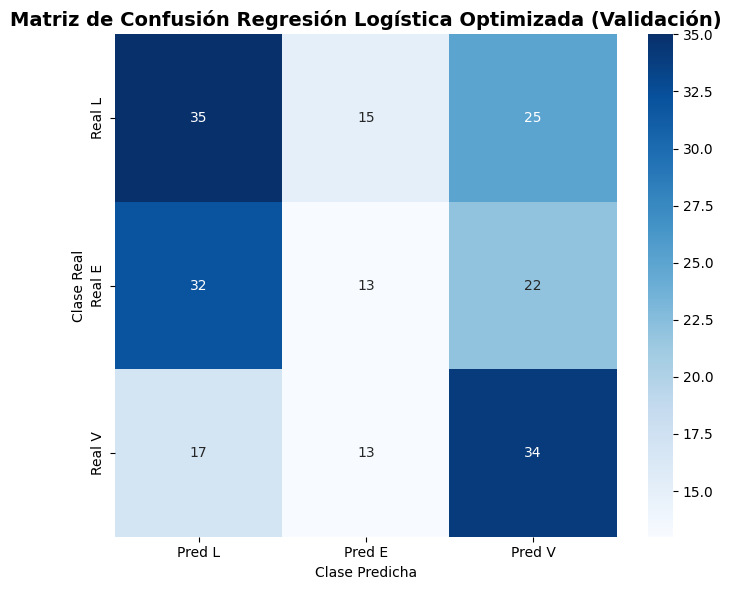

In [67]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_validacion_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Regresión Logística Optimizada (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "regresion_logistica_optimizada_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 25 Comparación base vs. optimizada
### 6.2. Comparación con el modelo inicial
Comparo la configuración seleccionada con la Regresión Logística inicial y con la línea base de clase mayoritaria.
Esta comparación me permite determinar si el proceso de regularización y ponderación de clases produjo una mejora real en el comportamiento global y, especialmente, en el equilibrio entre las categorías.

In [68]:
metricas_final_validacion = {
    "accuracy": accuracy_score(
        y_validacion,
        pred_validacion_final
    ),

    "precision_macro": precision_score(
        y_validacion,
        pred_validacion_final,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_validacion,
        pred_validacion_final,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_validacion,
        pred_validacion_final,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_validacion,
        proba_validacion_final,
        labels=modelo_seleccionado.named_steps[
            "modelo"
        ].classes_
    )
}

comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Baseline mayoritario",
        "Regresión Logística base",
        "Regresión Logística optimizada"
    ],

    "Accuracy": [
        baseline_validacion,
        metricas_base["accuracy"],
        metricas_final_validacion["accuracy"]
    ],

    "F1 Macro": [
        np.nan,
        metricas_base["f1_macro"],
        metricas_final_validacion["f1_macro"]
    ],

    "Log Loss": [
        np.nan,
        metricas_base["log_loss"],
        metricas_final_validacion["log_loss"]
    ]
})

display(
    comparacion_modelos.round(4)
)

,Modelo,Accuracy,F1 Macro,Log Loss
0,Baseline mayoritario,0.3641,NaN,NaN
1,Regresión Logística base,0.3738,0.3514,1.1326
2,Regresión Logística optimizada,0.3981,0.3833,1.0897


Celda 26 Preparación del entrenamiento final
## 7. Entrenamiento definitivo del modelo
Después de seleccionar la configuración mediante el conjunto de validación, considero finalizado el proceso de ajuste de hiperparámetros.
Para construir la versión definitiva de la Regresión Logística, uno los conjuntos de entrenamiento y validación. De esta manera aprovecho todos los partidos disponibles hasta finales de 2025 para ajustar el modelo antes de evaluar su comportamiento sobre los encuentros de 2026.
Mantengo sin modificar los hiperparámetros seleccionados anteriormente (`C = 0.005` y `class_weight = "balanced"`). El conjunto de prueba no interviene en ninguna decisión adicional.

In [69]:
df_train_final = pd.concat(
    [
        df_train,
        df_validacion
    ],
    ignore_index=True
)

df_train_final = (
    df_train_final
    .sort_values(
        [
            "fecha_partido",
            "registro_id"
        ]
    )
    .reset_index(drop=True)
)

X_train_final = (
    df_train_final[
        columnas_X
    ]
    .copy()
)

y_train_final = (
    df_train_final[
        "resultado"
    ]
    .copy()
)

print(
    "Partidos para entrenamiento final:",
    len(df_train_final)
)

print(
    "X_train_final:",
    X_train_final.shape
)

print(
    "y_train_final:",
    y_train_final.shape
)

print(
    "Fecha máxima de entrenamiento final:",
    df_train_final[
        "fecha_partido"
    ].max()
)

print(
    "Fecha mínima de prueba:",
    df_test[
        "fecha_partido"
    ].min()
)

Partidos para entrenamiento final: 2075
X_train_final: (2075, 48)
y_train_final: (2075,)
Fecha máxima de entrenamiento final: 2025-11-29 00:00:00
Fecha mínima de prueba: 2026-01-16 00:00:00


# Celda 27  Pipeline definitivo
### 7.1. Ajuste del Pipeline definitivo
Reconstruyo el Pipeline completo utilizando la configuración seleccionada.
El imputador, el escalado numérico y la codificación categórica se vuelven a ajustar utilizando exclusivamente los 2,075 encuentros correspondientes a entrenamiento y validación combinados. Posteriormente mantengo estas transformaciones fijas durante la evaluación sobre el conjunto de prueba.

In [70]:
modelo_final = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador
        ),
        (
            "modelo",
            LogisticRegression(
                C=0.005,
                class_weight="balanced",
                solver="lbfgs",
                max_iter=3000,
                random_state=42
            )
        )
    ]
)

modelo_final.fit(
    X_train_final,
    y_train_final
)

print(
    "Modelo definitivo entrenado correctamente."
)

Modelo definitivo entrenado correctamente.


# Celda 28 Única evaluación sobre prueba
## 8. Evaluación final sobre datos no observados
Una vez entrenada la configuración definitiva, evalúo por primera vez el modelo sobre el conjunto de prueba.
Este subconjunto contiene exclusivamente partidos de 2026 y 2026/2027 y no fue utilizado durante la selección de características, ajuste de hiperparámetros ni comparación de configuraciones.
Los resultados obtenidos en esta etapa representan la estimación final de la capacidad de generalización de la Regresión Logística sobre encuentros cronológicamente posteriores.

In [71]:
pred_test = (
    modelo_final.predict(
        X_test
    )
)

proba_test = (
    modelo_final.predict_proba(
        X_test
    )
)

metricas_test = {
    "accuracy": accuracy_score(
        y_test,
        pred_test
    ),

    "precision_macro": precision_score(
        y_test,
        pred_test,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_test,
        pred_test,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_test,
        pred_test,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_test,
        proba_test,
        labels=modelo_final.named_steps[
            "modelo"
        ].classes_
    )
}

for metrica, valor in metricas_test.items():
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3642
precision_macro: 0.3876
recall_macro: 0.3824
f1_macro: 0.3673
log_loss: 1.0910


# Celda 29 Comparación con baseline final
### 8.1. Comparación con la línea base
Comparo el desempeño final del modelo con la estrategia de predecir siempre la clase mayoritaria determinada a partir de los datos utilizados para entrenamiento.
Esta comparación me permite establecer si la Regresión Logística proporciona información predictiva adicional sobre partidos completamente posteriores al periodo utilizado para su ajuste.

In [72]:
clase_baseline_final = (
    y_train_final
    .value_counts()
    .idxmax()
)

baseline_test = (
    y_test
    .eq(
        clase_baseline_final
    )
    .mean()
)

print(
    "Clase baseline final:",
    clase_baseline_final
)

print(
    "Accuracy baseline prueba:",
    f"{baseline_test * 100:.2f}%"
)

print(
    "Accuracy Regresión Logística:",
    f"{metricas_test['accuracy'] * 100:.2f}%"
)

print(
    "Diferencia:",
    f"{(metricas_test['accuracy'] - baseline_test) * 100:.2f}",
    "puntos porcentuales"
)

Clase baseline final: L
Accuracy baseline prueba: 37.09%
Accuracy Regresión Logística: 36.42%
Diferencia: -0.66 puntos porcentuales


# Celda 30. Reporte de clasificación detallado en el conjunto de prueba (Test Set)
# 7.1. Métrica por clase y promedios globales en el conjunto de prueba
Para analizar el desempeño definitivo del modelo sobre los datos no observados de prueba (temporadas 2026 y 2026/2027), genero el reporte de clasificación completo con las métricas de precisión (Precision), sensibilidad (Recall) y puntuación F1 (F1-Score) para cada resultado ("L", "E", "V").

En esta celda utilizo classification_report con la opción output_dict=True para convertir los resultados en un DataFrame de pandas. Al transponer la tabla (.T) y redondear a cuatro decimales, obtengo una vista clara y estructurada de las métricas por categoría y de los promedios globales (macro avg y weighted avg).

In [73]:
# calcular el reporte de clasificación para la partición final de prueba
reporte_test = classification_report(
    y_test,
    pred_test,
    labels=[
        "L",
        "E",
        "V"
    ],
    output_dict=True,
    zero_division=0
)

# estructurar los resultados en un DataFrame para su visualización
df_reporte_test = (
    pd.DataFrame(
        reporte_test
    )
    .T
)

# mostrar la tabla de métricas redondeada
display(
    df_reporte_test.round(4)
)

,precision,recall,f1-score,support
L,0.5641,0.3929,0.4632,56.0000
E,0.3261,0.2542,0.2857,59.0000
V,0.2727,0.5000,0.3529,36.0000
accuracy,0.3642,0.3642,0.3642,0.3642
macro avg,0.3876,0.3824,0.3673,151.0000
weighted avg,0.4016,0.3642,0.3675,151.0000


# Celda 31 Matriz de confusión final

In [74]:
matriz_test = confusion_matrix(
    y_test,
    pred_test,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_test = pd.DataFrame(
    matriz_test,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_test
)

,Pred L,Pred E,Pred V
Real L,22,15,19
Real E,15,15,29
Real V,2,16,18


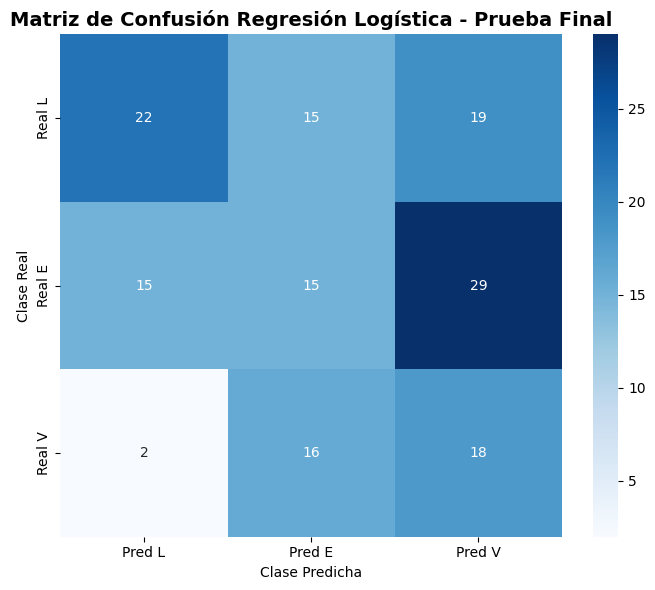

In [75]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Regresión Logística - Prueba Final",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

RUTA_FIGURA_TEST = (
    FIGURES_DIR
    / "regresion_logistica_prueba_final.png"
)

plt.savefig(
    RUTA_FIGURA_TEST,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 32. Comparación entre la distribución real y predicha en prueba (Test Set)
# 7.3. Auditoría de frecuencias de clase en el conjunto de prueba
Para verificar si el modelo tiende a sobrepredecir alguna categoría o si logra capturar el comportamiento de la variable objetivo en los partidos de prueba, comparo el conteo total de las clases reales frente a las predicciones generadas.

En esta celda construyo el DataFrame distribucion_test calculando las frecuencias con .value_counts() sobre y_test y pred_test. Reordeno explícitamente las categorías (["L", "E", "V"]) mediante .reindex() para asegurar una comparación directa y ordenada de la distribución observada contra la predicha.

In [76]:
# estructurar la tabla comparativa de frecuencias reales vs. predichas
distribucion_test = pd.DataFrame({
    "Real": (
        y_test
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_test
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

# mostrar la comparación de distribuciones en prueba
display(
    distribucion_test
)

,Real,Predicho
L,56,39
E,59,46
V,36,66


# Celda 33 Validación vs. prueba
### 8.2. Comparación entre validación y prueba
Comparo las métricas obtenidas durante la selección del modelo con las correspondientes al conjunto de prueba.

Una disminución del rendimiento en prueba no implica necesariamente un error de implementación, debido a que los partidos más recientes presentan una distribución diferente de resultados. Esta comparación me permite medir la estabilidad temporal del modelo.

In [77]:
comparacion_final = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "Log Loss"
    ],

    "Validación": [
        metricas_final_validacion[
            "accuracy"
        ],
        metricas_final_validacion[
            "precision_macro"
        ],
        metricas_final_validacion[
            "recall_macro"
        ],
        metricas_final_validacion[
            "f1_macro"
        ],
        metricas_final_validacion[
            "log_loss"
        ]
    ],

    "Prueba": [
        metricas_test[
            "accuracy"
        ],
        metricas_test[
            "precision_macro"
        ],
        metricas_test[
            "recall_macro"
        ],
        metricas_test[
            "f1_macro"
        ],
        metricas_test[
            "log_loss"
        ]
    ]
})

display(
    comparacion_final.round(4)
)

,Métrica,Validación,Prueba
0,Accuracy,0.3981,0.3642
1,Precision Macro,0.3845,0.3876
2,Recall Macro,0.3973,0.3824
3,F1 Macro,0.3833,0.3673
4,Log Loss,1.0897,1.0910


# Celda 34 Guardar modelo definitivo
## 9. Almacenamiento del modelo
Después de completar la evaluación final, almaceno el Pipeline completo mediante Joblib.

El archivo incluye tanto las transformaciones de preprocesamiento como la Regresión Logística entrenada. De esta manera puedo reutilizar posteriormente exactamente las mismas operaciones durante la implementación de la aplicación predictiva sin volver a ajustar los datos.

In [78]:
import joblib

RUTA_MODELO = (
    MODELS_DIR
    / "regresion_logistica_lpf.joblib"
)

joblib.dump(
    modelo_final,
    RUTA_MODELO
)

print(
    "Modelo guardado en:"
)

print(
    RUTA_MODELO
)

print(
    "Existe:",
    RUTA_MODELO.exists()
)

Modelo guardado en:
C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\regresion_logistica_lpf.joblib
Existe: True


## 10. Conclusión del modelo

Después de completar la selección de hiperparámetros y la evaluación sobre datos no observados, obtuve una Regresión Logística definitiva configurada con `C = 0.005` y ponderación balanceada de clases.

Durante la validación, el modelo alcanzó un Accuracy de 39.81 % y un F1-Score Macro de 38.33 %.  Al evaluarlo sobre los 151 partidos reservados como conjunto de prueba, obtuvo un Accuracy de 36.42 %, Precision Macro de 38.76 %, Recall Macro de 38.24 % y F1-Score Macro de 36.73 %.

La exactitud final quedó ligeramente por debajo del baseline de clase mayoritaria, establecido en 37.09 %. Sin embargo, a diferencia de esta estrategia trivial, la Regresión Logística generó predicciones para las tres clases de resultado.

Identifiqué como principal limitación la predicción de empates, cuyo F1-Score fue de 28.57 %. También observé una tendencia del modelo a sobreestimar las victorias visitantes, generando 66 predicciones de esta categoría frente a 36 casos reales.

Estos resultados indican que las relaciones entre las características prepartido y el resultado final presentan una complejidad que un modelo lineal como la Regresión Logística puede representar solamente de forma limitada. Conservo este modelo como referencia supervisada para compararlo posteriormente con algoritmos capaces de aprender relaciones no lineales, particularmente Random Forest y XGBoost.